# Лабораторная работа № 3 · Вариант 12
## Дифференцируемая оптимизация порядка переменных и выбор структурной причинной модели

**Основа:** `lab2_stress_tensor_RubtsovD.ipynb` и PDF «Лабораторная работа № 3».

**Задача:** адаптировать поиск порядка для порождения DAG, сохранять выборку графов,
передавать результаты интервенций в следующие шаги оптимизации и выбирать граф по точности,
сложности и устойчивости. Дополнительно разобрать отличие выбора предиктора от выбора SCM.

Работа продолжает физическую постановку ЛР2.

**Запуск:** открыть этот ноутбук рядом с `lab2_core.py`, `lab3_core.py`, `lab3_plots.py` и выполнить Run All.
Необходимы Python ≥ 3.10, NumPy, SciPy, pandas, matplotlib, Jupyter. Данные уже встроены,
интернет и GPU для расчёта не нужны. При повторном запуске перезаписываются только созданные результаты.


In [1]:
from pathlib import Path
import sys, json, platform
import numpy as np, pandas as pd, scipy, matplotlib.pyplot as plt
from IPython.display import display
import lab2_core as previous
import lab3_core as core
import lab3_plots as plots
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 5)
print('Python:', platform.python_version())
print('NumPy:', np.__version__, '| SciPy:', scipy.__version__, '| pandas:', pd.__version__)


Python: 3.13.9
NumPy: 2.3.5 | SciPy: 1.16.3 | pandas: 2.3.3


## 1. Уравнение из исходной лабораторной

Однородное одноосное растяжение несжимаемого материала:
$$F=\operatorname{diag}(\lambda,\lambda^{-1/2},\lambda^{-1/2}),\quad
s=I_1-3=\lambda^2+2/\lambda-3.$$
Уравнение равновесия $\operatorname{Div}P=0$ выполняется автоматически в однородном случае.
Энергия Yeoh второго порядка и номинальное напряжение:
$$W=C_{10}s+C_{20}s^2,\qquad
P=\frac{d\widehat W}{d\lambda}=2(\lambda-\lambda^{-2})(C_{10}+2C_{20}s).$$
Давление несжимаемости исключено с учётом свободных боковых поверхностей.
$\lambda,s$ безразмерны, $W,C_{10},C_{20},P$ измеряются в MPa.

Сравниваем **Yeoh-2** и **Yeoh-1** ($C_{20}=0$). Сокращённый закон остаётся нелинейным по $\lambda$.
Из исходного ноутбука сохранены вычислительный граф, forward-mode дифференцирование,
байесовская идентификация, MH и диагностики в отдельном `lab2_core.py`.


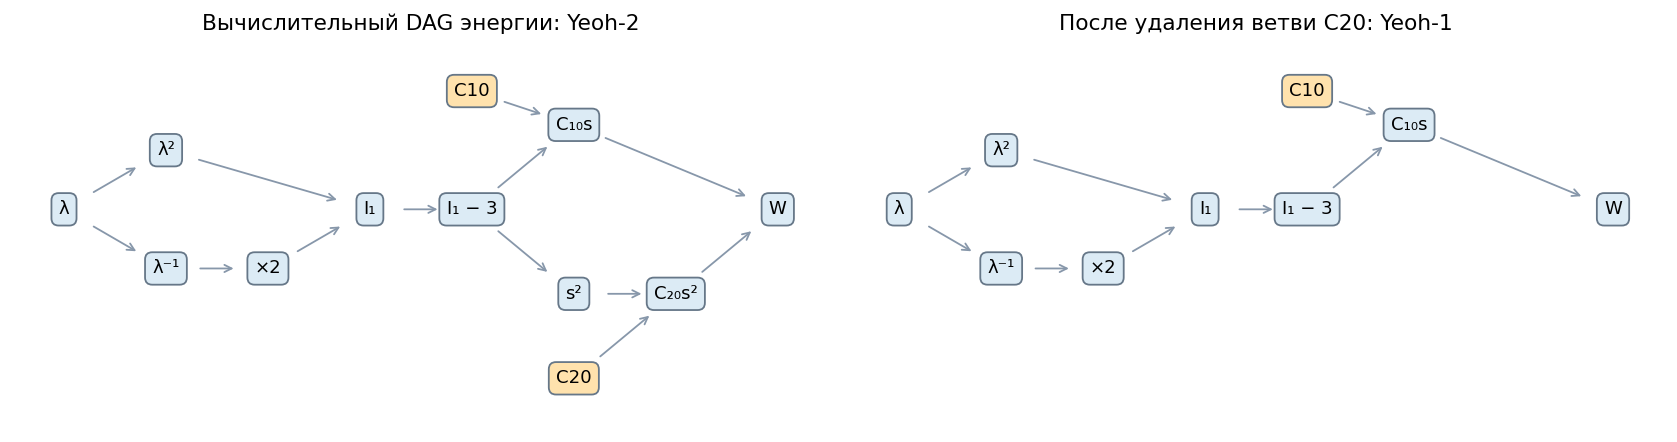

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
previous.draw_graph(axes[0], False); previous.draw_graph(axes[1], True)
axes[0].set_title('Вычислительный DAG энергии: Yeoh-2')
axes[1].set_title('После удаления ветви C20: Yeoh-1')
plt.tight_layout(); plt.show()


## 2. Где появляется причинно-следственная модель

Вычислительный граф операций сам по себе ещё не устанавливает причинность.
Вводим **ограниченную механистическую SCM**, предполагая, что экспериментатор задаёт растяжение,
материал квазистатичен, несжимаем и описывается выбранным классом энергий:
$$\lambda:=U_\lambda,\quad s:=\lambda^2+2/\lambda-3,\quad
K:=C_{10}+2C_{20}s,\quad P:=2(\lambda-\lambda^{-2})K,$$
$$P_{meas}:=P+\varepsilon,\quad\varepsilon\sim N(0,\sigma^2).$$
$K$ — эффективный множитель жёсткости, а не отдельно измеренная переменная; $s$ вычисляется по $\lambda$.
В макрографе используем четыре вершины $(\lambda,s,K,P)$; измерительный узел одинаков для всех кандидатов
и в поиске не участвует. $C_{10},C_{20}$ — параметры механизмов, не переменные порядка.

Обязательны рёбра $\lambda\to s$, $\lambda\to P$, $K\to P$.
Выбираем наличие ребра **$s\to K$**, эквивалентное сохранению ветви $C_{20}s^2$ в энергии.
При $C_{20}=0$ вершину $s$ можно удалить как неиспользуемую; в пространстве порядков она оставлена
для одинаковой размерности состояний. Латентные $K$ не восстанавливаются как независимые данные.

**Принципиальная граница:** направление «деформация → напряжение» здесь задано механикой и протоколом.
По десяти наблюдениям Treloar причинные направления не идентифицируются без предпосылок.
Работа выбирает допустимую структуру механизма внутри этой SCM, а не доказывает полное causal discovery.


## 3. Данные, разделение и заранее фиксированные настройки

Как в ЛР2: Treloar — 10 цифровых точек одноосного растяжения в диапазоне $1<\lambda\le6$,
источник CANN (конкретный commit указан в источниках); $\sigma=0.08$ MPa — рабочий масштаб
ошибки модели, а не заявленная точность прибора. Два синтетических контроля по 30 точек,
$C_{10}=0.2$ MPa, $C_{20}=0$ или $0.002$ MPa, шум $\sigma=0.03$ MPa, seed=42.

Исходный test сохранён: каждая четвёртая точка с индексом 3 mod 4. Из оставшихся точек каждая третья
по порядку выделяется под validation. Параметры оцениваются **только на train**, структура и все критерии
считаются на validation; test используется один раз после выбора. Это чередующиеся диапазоны,
а не проверка экстраполяции. Очень маленький test Treloar ограничивает обобщаемость результата.

Фиксированы: $\alpha=0.10$, $\beta=0.05$, KL-регуляризация $\tau=0.05$, 3 стадии × 120 шагов Adam,
16 графов на шаг. Это учебные настройки, не подобранные по test. 12 фиксированных вложенных масок,
доли зануления $q=0.25,0.5$; $\lfloor qn_{train}\rfloor$ точек. Фактические доли сохраняются в CSV.


In [3]:
data = core.datasets()
display(pd.DataFrame([{'Данные': name, 'train': core.split(len(x))[0].sum(),
                      'validation': core.split(len(x))[1].sum(), 'test': core.split(len(x))[2].sum(),
                      'sigma, MPa': sd} for name, (x,y,sd) in data.items()]))
print('alpha =', core.ALPHA, 'beta =', core.BETA, 'tau =', core.TAU)


,Данные,train,validation,test,"sigma, MPa"
0,Контроль C20=0,16,7,7,0.03
1,Контроль C20=0.002,16,7,7,0.03
2,Treloar,6,2,2,0.08


alpha = 0.1 beta = 0.05 tau = 0.05


## 4. Пункт 12: дифференцируемая оптимизация порядка

Опираемся на принцип order-based learning: сначала порядок, затем согласованные с ним рёбра.
Источники — Zantedeschi et al., *DAG Learning on the Permutahedron* (ICLR 2023)
и Charpentier et al., *Differentiable DAG Sampling* (ICLR 2022).
**Ниже собственная малая адаптация этого принципа; это не воспроизведение DAGuerreotype / SparseMAP / VI-DP-DAG.**

Из $4!=24$ порядков и двух состояний ветви получаем 48 пар; физические ограничения оставляют
**6 допустимых состояний: 5 порядков Yeoh-1 и 1 порядок Yeoh-2. Структур всего две.**
Перебор здесь нужен для точного математического ожидания и проверки корректности, а не заменяет
обновление параметров распределения.

Для $o$ обозначим $\rho_i(o)$ позицию узла $i$, делённую на 3, а $b\in\{0,1\}$ — наличие ветви.
Параметры поиска — непрерывные $r\in\mathbb R^4$ и $a\in\mathbb R$:
$$q_{r,a}(o,b)=\operatorname{softmax}_{(o,b)\in\mathcal S}
\left[\log q_0(o,b)+r^T\rho(o)+ab\right],\qquad
q_0(o,b)=\frac{1}{2N_b}.$$
$N_b$ — число допустимых порядков соответствующей структуры. Поэтому пять сортировок сокращённого
графа не дают ему пятикратное исходное преимущество. Большая оценка $r_i$ предпочитает позднюю позицию узла.

$$\mathcal L(r,a)=\sum_{s\in\mathcal S}q_sJ_s+
\tau\operatorname{KL}(q\|q_0)+0.001\|(r,a)\|^2.$$
Если $f_s=(\rho(o),b)$, то
$$\nabla\mathcal L=\sum_s q_s(f_s-E_qf)
\big[J_s+\tau(\log q_s-\log q_{0s}+1)\big]+0.002(r,a).$$
Веса механизмов переоцениваются отдельно; внешняя конечная сумма дифференцируется аналитически.
Не требуется дифференцировать `argsort`, дискретный граф или MH. Нет straight-through оценки градиента.

**Корректность:** всякое ребро направлено от меньшей позиции к большей; цикл потребовал бы
$\rho_{i_1}<\cdots<\rho_{i_1}$ — противоречие. Маска поддержки оставляет только разрешённые механизмы.
Каждый полученный граф ацикличен и физически осмыслен в принятой параметризации.
Это гарантия допустимости, не доказательство глобальной сходимости Adam или истинности причинного графа.
Точный перебор конечного класса даёт контроль лучшей структуры; масштабирование на большие DAG
потребует другого способа вычисления ожидания. Для этой малой задачи перебор проще, но реализован
именно требуемый дифференцируемый поиск порядка.


In [4]:
display(pd.DataFrame([{'Порядок': ' → '.join(core.NODES[i] for i in o),
                       'Структура': 'Yeoh-2' if b else 'Yeoh-1'} for o,b in core.STATES]))
# Проверка аналитического градиента — центральные конечные разности.
z = np.array([.2, -.3, .1, .4, -.2]); costs = np.array([1., 2., 1., 1., 1., 1.])
value, analytical, probs = core.objective(z, costs)
h = 1e-5
numerical = np.array([(core.objective(z + h*np.eye(5)[i], costs)[0] -
                       core.objective(z - h*np.eye(5)[i], costs)[0])/(2*h) for i in range(5)])
assert np.allclose(analytical, numerical, atol=1e-7, rtol=1e-5)
assert np.isclose(core.objective(np.zeros(5), costs)[2][1], .5)
assert all(core.compatible(o,b) for o,b in core.STATES)
print('Градиент проверен; max |ошибка| =', np.max(abs(analytical-numerical)))


,Порядок,Структура
0,lambda → s → K → P,Yeoh-1
1,lambda → s → K → P,Yeoh-2
2,lambda → K → s → P,Yeoh-1
3,lambda → K → P → s,Yeoh-1
4,K → lambda → s → P,Yeoh-1
5,K → lambda → P → s,Yeoh-1


Градиент проверен; max |ошибка| = 2.2737561833352515e-11


## 5. Целевая функция и добавление выбора SCM

Для структуры $G$ на чистом train находим апостериорное среднее $\hat\theta_G$.
Используем тот же Gaussian prior, что в ЛР2:
$C_{10}\sim N(0.2,0.3^2)$, $C_{20}\sim N(0,0.02^2)$.
Для Yeoh-1 оставляем только первый параметр. Линейно-гауссовый posterior вычисляется точно;
MH используется ниже для продолжения проверки из ЛР2, а не для оптимизации порядка.

$$A_G=\frac1{n_v}\sum_{i\in val}
\left[\frac{P_G(\lambda_i;\hat\theta_G)-y_i}{\sigma}\right]^2,\quad C_G=\dim\theta_G,$$
$$R_G=\frac1{|\mathcal E|}\sum_{e\in\mathcal E}\frac1{n_v}\sum_{i\in val}
\left[\frac{P_G(\lambda_i;\hat\theta_{G,e})-P_G(\lambda_i;\hat\theta_G)}{\sigma}\right]^2,$$
$$J_G=A_G+0.10C_G+0.05R_G.$$
$\hat\theta_{G,e}$ — posterior mean после зануления части **обучающих** напряжений, включая нулевые точки
в подгонку. $R_G$ — устойчивость переидентификации модели, не физическая инвариантность материала.

Стадии: (1) чистые данные, $R_G=0$; (2) 12 масок при $q=0.25$; (3) обе доли, 24 среды.
На следующей стадии новые значения $R_G$ входят в градиент распределения порядков и ветви.
На каждом шаге семплируются и сохраняются 16 DAG. Это направленная оптимизационная выборка,
**не MCMC и не байесовский posterior по графам**. Все среды вычисляются заранее детерминированно;
в оптимизацию они включаются по стадиям, обратная связь использует их накопленный результат.

**Что добавлено к обычному ML:** фиксируем механизмы SCM и допустимые направления; проверяем отдельную
ветвь через правило ЛР2; учитываем устойчивость к повреждению измерительного механизма;
после выбора можем выполнять структурные вмешательства с сохранением остальных механизмов.
Одной надбавки $R_G$ к MSE недостаточно для доказательства причинности.

Правило ЛР2 перенесено на validation: удалить C20 разрешается, если его 95% credible interval
содержит ноль, рост RMSE ≤ 0.02 MPa и сокращённый средний закон физически допустим.
Для каждого итогового закона требуем $C_{10}>0$ и $dP/d\lambda>0$ на сетке $[1,6]$.
Сетка — локальная проверка, не доказательство глобальной устойчивости. В ЛР2 интервал оценивался
по MH; здесь используем его точный Gaussian аналог. Это устраняет шум семплирования в решении.

**Окончательный отбор:** среди реально сгенерированных структур, прошедших физическую проверку
и запрет необоснованного удаления, выбирается минимальное $J_G$.
Базовый ML-вариант использует только $A_G+0.10C_G$.


In [5]:
runs, summary, metrics, mh_diagnostics, ks = core.run('results')
display(metrics[['dataset','full','C10','C20','val_rmse','accuracy','complexity','robustness','score']])
print('Сохранены все графы, порядки, рёбра, вероятности, критерии и маски в results/.')
display(summary)


,dataset,full,C10,C20,val_rmse,accuracy,complexity,robustness,score
0,Контроль C20=0,False,0.19939,0.00000,0.02702,0.81128,1,343.30069,18.07631
1,Контроль C20=0,True,0.19679,0.00006,0.03152,1.10414,2,389.18911,20.76360
2,Контроль C20=0.002,False,0.28597,0.00000,0.24836,68.53382,1,699.80126,103.62388
3,Контроль C20=0.002,True,0.20169,0.00197,0.02125,0.50183,2,735.15592,37.45963
4,Treloar,False,0.18046,0.00000,0.15159,3.59053,1,28.77616,5.12933
5,Treloar,True,0.13188,0.00103,0.06676,0.69634,2,31.31117,2.46190


Сохранены все графы, порядки, рёбра, вероятности, критерии и маски в results/.


,dataset,n_train,n_val,n_test,chosen,ml_baseline,C20_low,C20_high,removal_allowed,val_rmse,test_rmse,score,unique_orders,sampled_graphs,unique_structures
0,Контроль C20=0,16,7,7,Yeoh-1,Yeoh-1,-0.00004,0.00016,True,0.02702,0.01868,18.07631,5,5760,2
1,Контроль C20=0.002,16,7,7,Yeoh-2,Yeoh-2,0.00187,0.00207,False,0.02125,0.02465,37.45963,5,5760,2
2,Treloar,6,2,2,Yeoh-2,Yeoh-2,0.00056,0.00150,False,0.06676,0.05762,2.46190,5,5760,2


## 6. Аппроксимация реальных данных и контролей

Кривые оценены только по train. Квадраты — validation для выбора структуры, кресты — test.
Никакие test-точки не участвуют в оценке параметров, интервенциях или выборе графа.


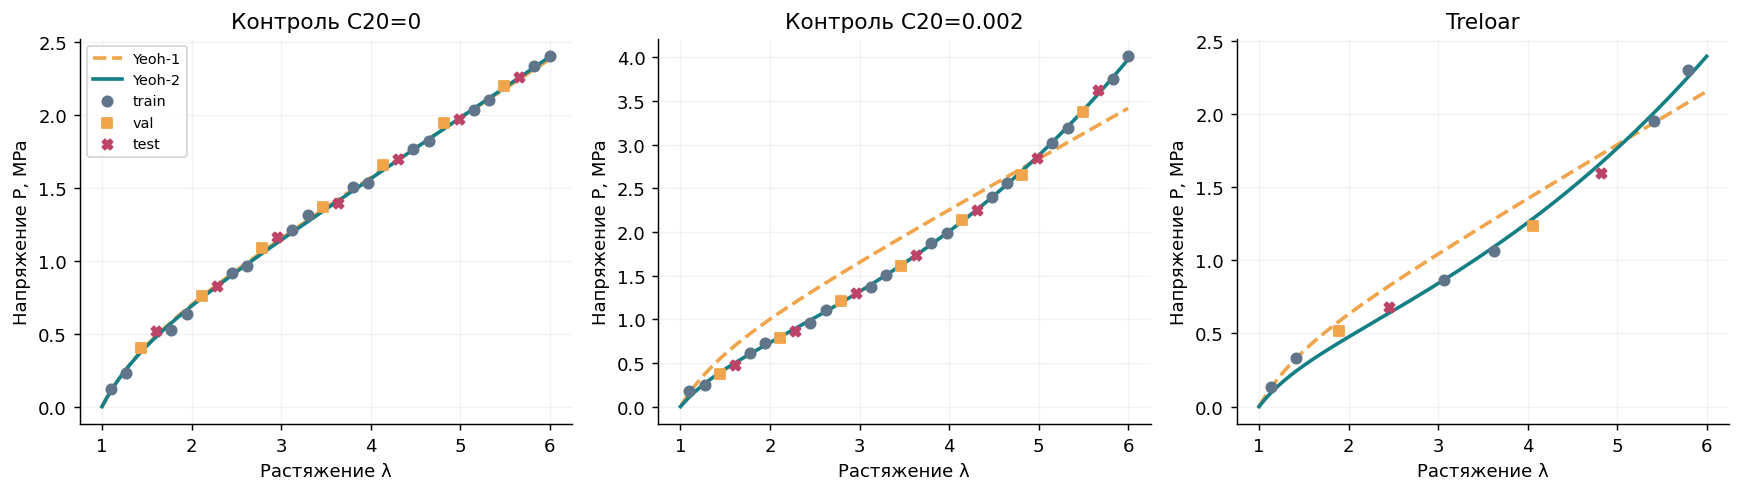

In [6]:
plots.fits(runs); plt.show()

## 7. Как меняется распределение генерируемых графов

На графике вероятность полной структуры суммирована по её допустимым порядкам.
Вертикальные линии — включение новых интервенционных сред. Значение функции на разных стадиях
может возрастать из-за изменения задачи. Справа показан зазор ожидаемой стоимости до минимума
текущей стадии; это диагностический график, не доказательство сходимости.


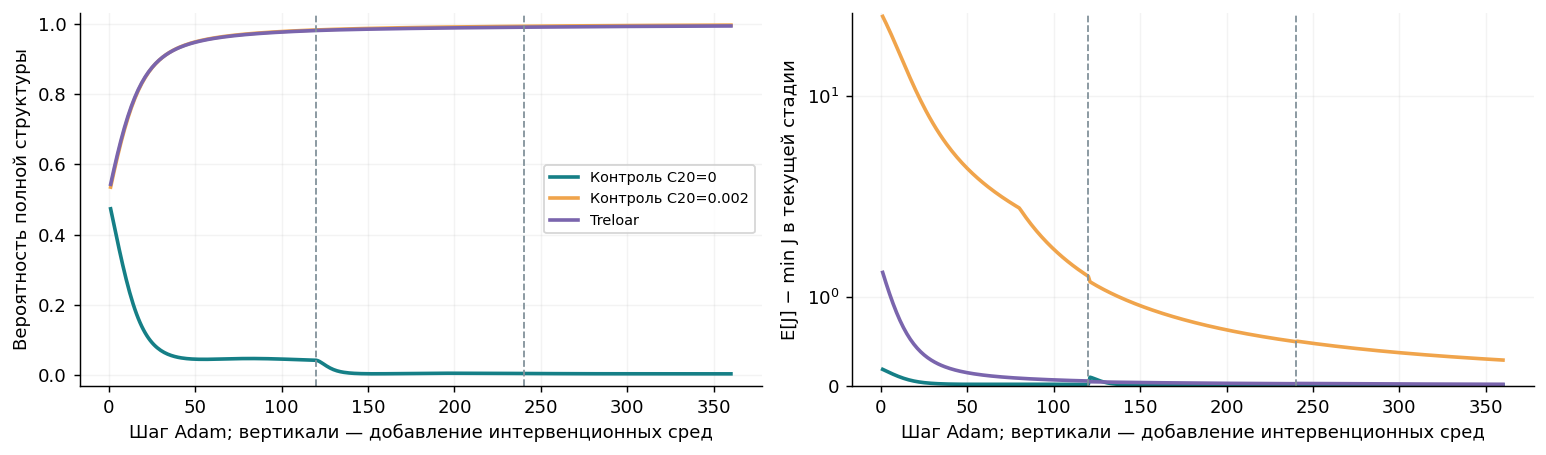

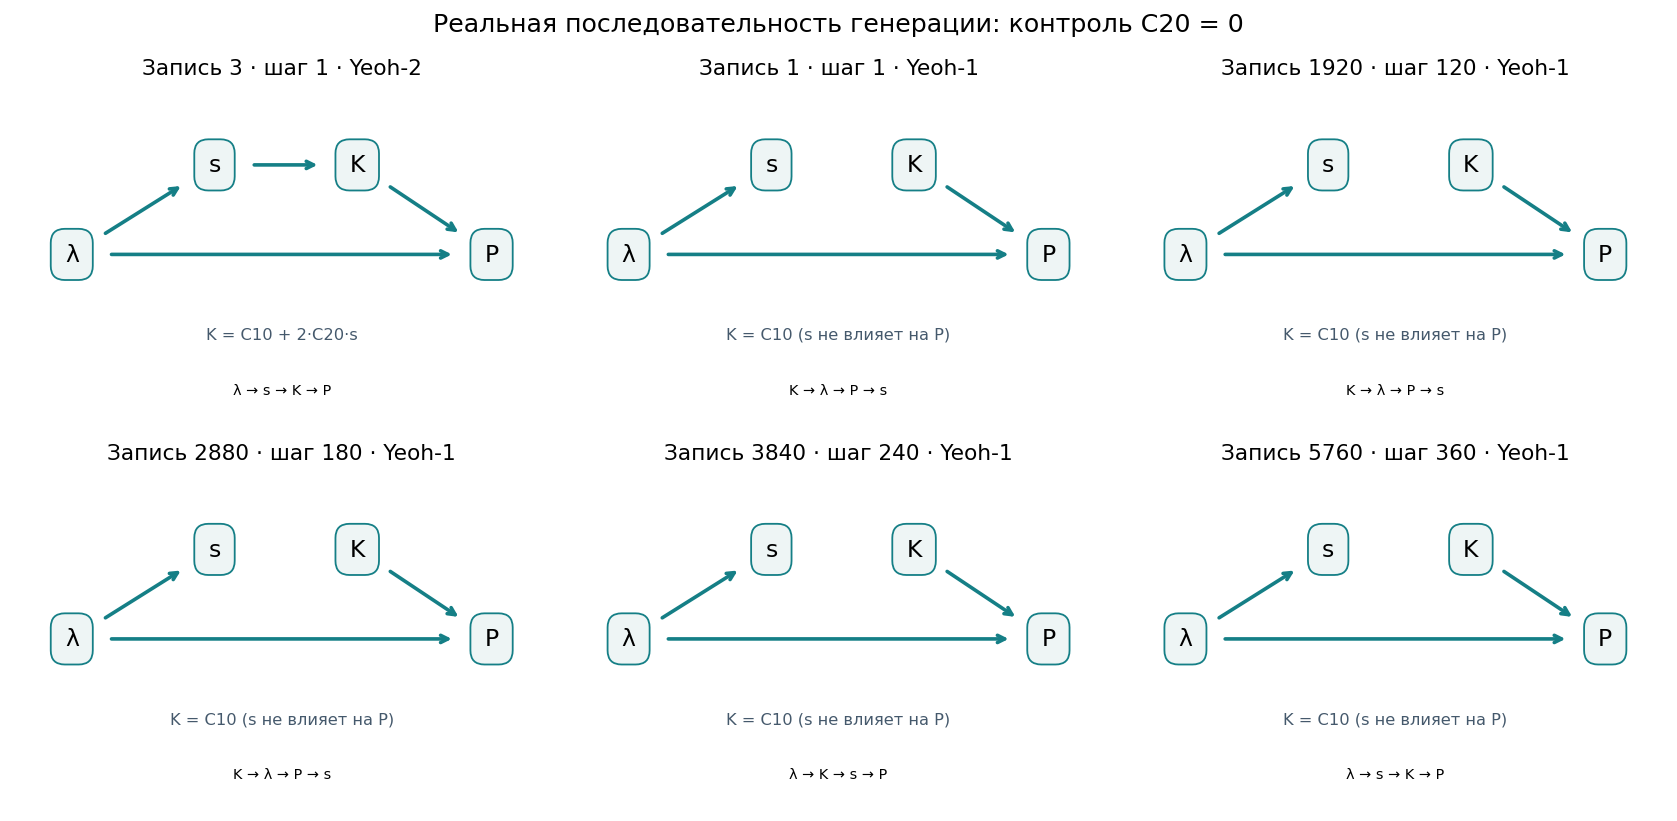

In [7]:
plots.convergence(runs); plt.show()
plots.graph_sequence(runs); plt.show()

На последовательности приведены настоящие записи сохранённого журнала для контроля C20=0.
Первые две записи выбраны так, чтобы показать обе структуры, остальные — временные срезы.
Отличающиеся порядки одного графа считаются одной структурой. Все 5760 записей каждого набора
сохранены без удаления повторов — повторы показывают концентрацию распределения поиска.

## 8. Интервенции, критерии и результат

На графике устойчивости линия — корень из среднего нормированного квадратичного сдвига
прогнозов; полупрозрачные точки — RMS для каждой из 12 масок.
Зануление существенно повреждает задачу; большая устойчивость не заменяет точность.
В составном критерии виден вклад каждого компонента, включая масштаб штрафа устойчивости.


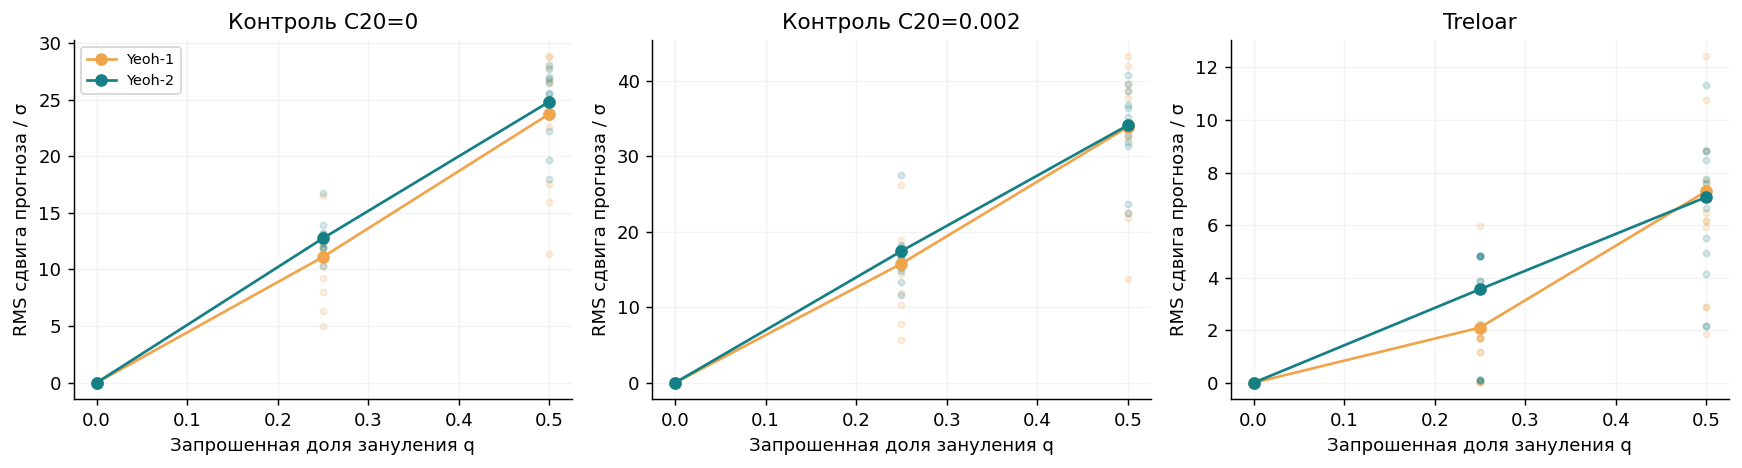

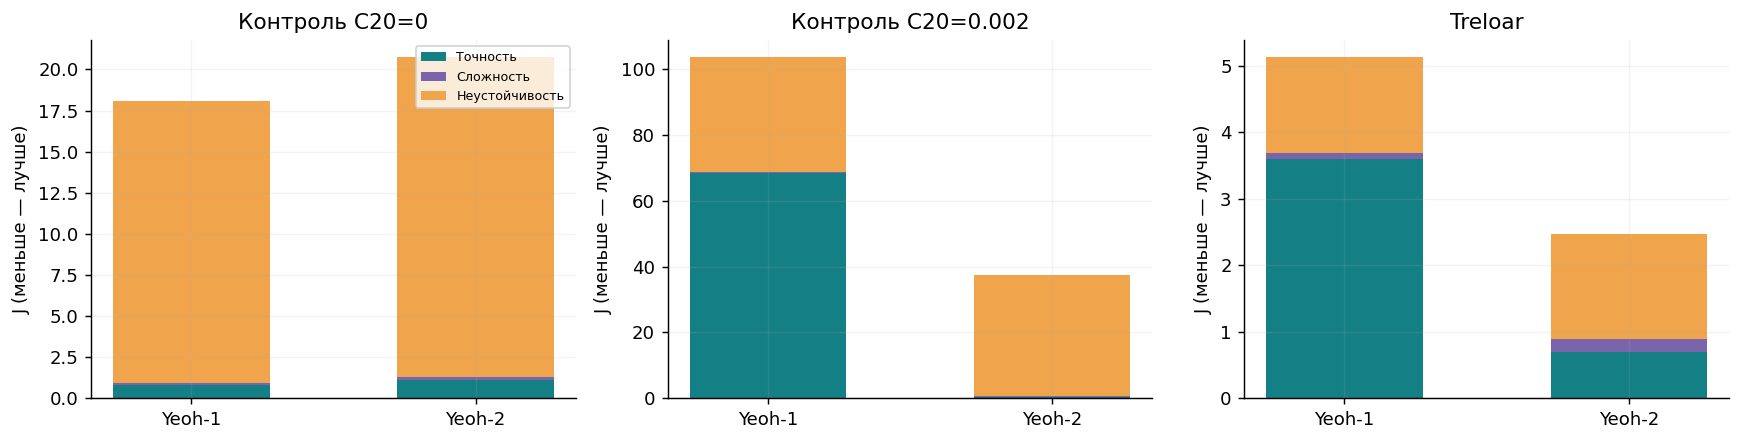

In [8]:
plots.interventions(runs); plt.show()
plots.scores(metrics); plt.show()

In [9]:
display(summary[['dataset','chosen','ml_baseline','C20_low','C20_high','removal_allowed',
                 'val_rmse','test_rmse','unique_orders','unique_structures','sampled_graphs']])
for row in summary.itertuples():
    print(f'{row.dataset}: {row.chosen}; test RMSE={row.test_rmse:.5f} MPa; '
          f'95% CI C20=[{row.C20_low:.6f}, {row.C20_high:.6f}] MPa.')
assert summary.iloc[0].chosen == 'Yeoh-1'
assert summary.iloc[1].chosen == 'Yeoh-2'
assert mh_diagnostics.rhat.max() < 1.05


,dataset,chosen,ml_baseline,C20_low,C20_high,removal_allowed,val_rmse,test_rmse,unique_orders,unique_structures,sampled_graphs
0,Контроль C20=0,Yeoh-1,Yeoh-1,-0.00004,0.00016,True,0.02702,0.01868,5,2,5760
1,Контроль C20=0.002,Yeoh-2,Yeoh-2,0.00187,0.00207,False,0.02125,0.02465,5,2,5760
2,Treloar,Yeoh-2,Yeoh-2,0.00056,0.00150,False,0.06676,0.05762,5,2,5760


Контроль C20=0: Yeoh-1; test RMSE=0.01868 MPa; 95% CI C20=[-0.000041, 0.000163] MPa.
Контроль C20=0.002: Yeoh-2; test RMSE=0.02465 MPa; 95% CI C20=[0.001866, 0.002070] MPa.
Treloar: Yeoh-2; test RMSE=0.05762 MPa; 95% CI C20=[0.000562, 0.001496] MPa.


**Интерпретация:** контроль C20=0 проверяет удаление избыточной ветви;
контроль C20=0.002 проверяет сохранение нужного механизма. На Treloar выбран Yeoh-2 в исследованном
диапазоне. Полный и сокращённый законы согласуются с известной физикой, но хуже предсказывающий
не становится от этого лучшей моделью.

В данном запуске ML-базовый отбор и расширенный SCM-отбор выбрали одинаковые структуры.
Это **не демонстрация превосходства по точности**. Добавлены процедура проверки механизма,
анализ устойчивости и явная семантика вмешательств. На таком маленьком пространстве графов
дифференцируемый метод не имеет вычислительного преимущества перед перебором.

## 9. Чувствительность к весу устойчивости

Меняем только beta по заранее указанной сетке; test не пересчитывается и не используется для выбора.
Показываем решение до и после ограничения удаления ветви из ЛР2. Значительное увеличение beta
может сделать неточную сокращённую модель предпочтительной по голой сумме; структурное правило
защищает обнаруженный механизм. Это диагностическая таблица, итоговые настройки не меняются.

In [10]:
sensitivity = []
for name, r in runs.items():
    can_remove, _, _ = core.lab2_rule(r['models'])
    for beta in [0., .01, .05, .1, .5, 2.]:
        score = lambda m: m['accuracy'] + core.ALPHA*m['complexity'] + beta*m['robustness']
        raw = min(r['models'], key=score)
        allowed = [m for m in r['models'] if m['physical'] and (m['full'] or can_remove)]
        final = min(allowed, key=score)
        sensitivity.append({'Данные':name,'beta':beta,
                            'Только сумма':'Yeoh-2' if raw['full'] else 'Yeoh-1',
                            'С правилом ЛР2':'Yeoh-2' if final['full'] else 'Yeoh-1'})
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity)
sensitivity.to_csv('results/sensitivity.csv', index=False)


,Данные,beta,Только сумма,С правилом ЛР2
0,Контроль C20=0,0.00,Yeoh-1,Yeoh-1
1,Контроль C20=0,0.01,Yeoh-1,Yeoh-1
2,Контроль C20=0,0.05,Yeoh-1,Yeoh-1
3,Контроль C20=0,0.10,Yeoh-1,Yeoh-1
4,Контроль C20=0,0.50,Yeoh-1,Yeoh-1
5,Контроль C20=0,2.00,Yeoh-1,Yeoh-1
6,Контроль C20=0.002,0.00,Yeoh-2,Yeoh-2
7,Контроль C20=0.002,0.01,Yeoh-2,Yeoh-2
8,Контроль C20=0.002,0.05,Yeoh-2,Yeoh-2
9,Контроль C20=0.002,0.10,Yeoh-2,Yeoh-2


## 10. MH и KS из предыдущей работы

Для каждого набора сравниваем чистый train и одну фиксированную маску $q=0.5$.
Используются исходные MH и диагностики: 4 цепи, 1000 шагов прогрева и 4000 сохранённых состояний.
Split-Rhat обычный, не rank-normalized; ESS — приближённая оценка по автокорреляции.
Точное Gaussian решение позволяет дополнительно проверить ошибку среднего в единицах posterior SD.

KS-расстояние $D$ считаем на зависимых состояниях MH как описательную меру. Формальный p-value
получен на двух независимых iid-выборках по 500 значений из точных posterior; поправка Бонферрони
на 6 тестов (3 набора × 2 параметра). Здесь p-value относится к параметрической модели и заданным
posterior, не к доказательству причинного эффекта. KS не служит критерием удаления ветви.


In [11]:
display(mh_diagnostics)
display(ks)

,dataset,q,acceptance,rhat,ess,mean_error_sd
0,Контроль C20=0,0.0,0.36062,1.00074,2162.45915,0.02469
1,Контроль C20=0,0.5,0.35387,1.00059,2243.44884,0.02093
2,Контроль C20=0.002,0.0,0.35475,1.00194,2178.61502,0.01762
3,Контроль C20=0.002,0.5,0.34963,1.00328,2176.46512,0.00194
4,Treloar,0.0,0.35969,1.00089,2176.51720,0.00536
5,Treloar,0.5,0.35537,1.00113,1919.89943,0.04167


,dataset,parameter,D_MH,p_iid,p_bonferroni
0,Контроль C20=0,C10,1.00000,7.39951e-300,4.43970e-299
1,Контроль C20=0,C20,0.98988,3.69605e-294,2.21763e-293
2,Контроль C20=0.002,C10,1.00000,7.39951e-300,4.43970e-299
3,Контроль C20=0.002,C20,1.00000,7.39951e-300,4.43970e-299
4,Treloar,C10,0.99606,7.39951e-300,4.43970e-299
5,Treloar,C20,1.00000,7.39951e-300,4.43970e-299


## 11. Физическое вмешательство и повреждение измерения — разные операции

При $do(\lambda=a)$ заменяем первое структурное уравнение константой и пересчитываем
$s,K,P$ при прежних параметрах материала. При $do(P_{meas}=0)$ меняется только измерительный узел:
истинное $P$, $K$, $s$ и растяжение остаются прежними. Повторная подгонка по испорченным показаниям
может поменять **наши оценки**, но не материал.

Следующий график — расчётные предсказания принятой SCM, а не реально проведённый
интервенционный эксперимент. Нельзя выдавать их за независимую проверку причинного направления.
Для такой проверки нужны новые управляемые опыты и, например, другой режим нагружения.


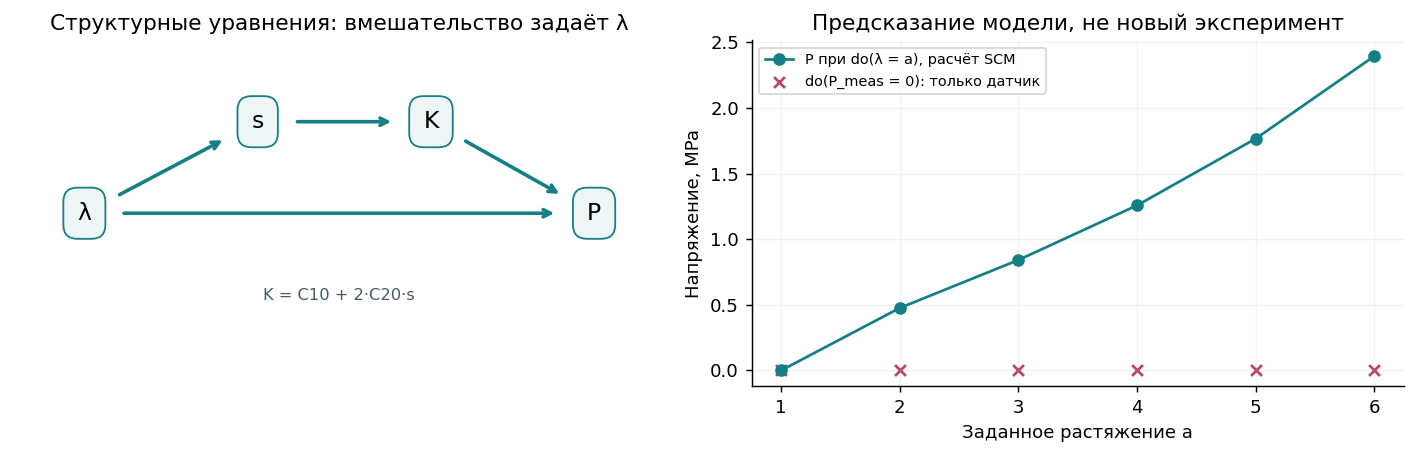

In [12]:
plots.causal_semantics(runs); plt.show()

## 12. Выводы, ограничения и соответствие требованиям

1. Реализован вариант 12: непрерывные оценки порядка, точный дифференцируемый функционал,
обновление Adam и семплирование дискретных DAG. Градиент проверен конечными разностями.
2. Получены и сохранены 17 280 графов (3 × 5760), включая порядки, рёбра, вероятности и критерии.
Это выборка с повторами из двух структур, а не 17 280 различных причинных моделей.
3. Интервенционные среды влияют на следующую стадию оптимизации; при окончательном выборе
учтены точность, число параметров, устойчивость и правило ЛР2 для отдельной ветви.
4. Два синтетических контроля восстановили заданное наличие/отсутствие ветви C20.
На Treloar в диапазоне λ≤6 выбран Yeoh-2. Числа RMSE и интервалы приведены в вычисленных таблицах.
5. Структурный отбор использует SCM, явный объект выбора, ограничения
на направления и различение физических вмешательств и повреждений датчика.

Ограничения: всего две структуры; существенная часть порядка задана физикой; порядки одного графа
неидентифицируемы; мало реальных данных (6 train / 2 validation / 2 test); нет новых физических опытов;
постоянный масштаб ошибки; normal prior допускает нефизические промежуточные параметры;
12 масок характеризуют только выбранную схему повреждения; нет доказательства глобальной сходимости.
Сходство результата с ML-базовым методом не доказывает преимущества причинного отбора.
Дополнительные режимы растяжения, больше данных и новые вмешательства нужны для расширения вывода.

| Требование PDF | Реализация |
|---|---|
| Уравнение и правило из предыдущей работы | Разделы 1 и 5, lab2_core.py |
| Реальные данные и интервенции | Разделы 3, 5, 8, 10 |
| Алгоритм генерации и корректность | Раздел 4, аналитический градиент и проверка |
| Точность, сложность, устойчивость | J в разделе 5 |
| Последовательность графов | Раздел 7 и все CSV |
| Данные и аппроксимация | Раздел 6 |
| Повторное использование кода | Три независимых модуля, исходный ipynb сохранён |
| Презентация и устный доклад | presentation.pptx, presentation.pdf, speaker_script.md |


## Источники

1. Локальный PDF «Лабораторная работа № 3», с. 1–2 (требования и вариант 12).
2. `lab2_stress_tensor_RubtsovD.ipynb`: физическая постановка, данные и критерий ветви.
3. Zantedeschi V. et al. (2023). [DAG Learning on the Permutahedron](https://arxiv.org/abs/2301.11898).
Принцип оптимизации топологического порядка и условного выбора рёбер.
4. Charpentier B., Kibler S., Günnemann S. (2022). [Differentiable DAG Sampling](https://arxiv.org/abs/2203.08509).
Разложение генерации на порядок и согласованные рёбра.
5. Treloar L.R.G. (1944). [Stress-strain data for vulcanised rubber under various types of deformation](https://doi.org/10.1039/TF9444000059).
6. [Цифровая таблица CANN, точная версия](https://github.com/LivingMatterLab/CANN/blob/a639ea97acfa1064005381645c1a2fda74bcbfcd/GICANN/input/CANNsRUBBERdata.xlsx).
Значения перенесены из исходного ноутбука, не оцифровывались повторно.
7. Yeoh O.H. (1993). [Some forms of the strain energy function for rubber](https://doi.org/10.5254/1.3538343).
8. Hastings W.K. (1970). [Monte Carlo sampling methods using Markov chains and their applications](https://doi.org/10.1093/biomet/57.1.97).
9. Pearl J. (2009). [Causality, 2nd ed.](https://doi.org/10.1017/CBO9780511803161).
Семантика структурных уравнений и вмешательства do.
